<a href="https://colab.research.google.com/github/Vishali-Vivek006/Engineering-employability-prediction/blob/main/notebooks/02_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
from IPython.display import display

print("Upload your Employability_dataset.csv file")
uploaded = files.upload()

csv_files = [name for name in uploaded if name.lower().endswith(".csv")]

if not csv_files:
    raise ValueError("No CSV file uploaded. Please upload Employability_dataset.csv.")

df = pd.read_csv(csv_files[0])

print("Dataset loaded successfully!")
print("File:", csv_files[0])
print("Dataset shape:", df.shape)

display(df.head())

Upload your Employability_dataset.csv file


Saving Employability_dataset.csv to Employability_dataset.csv
Dataset loaded successfully!
File: Employability_dataset.csv
Dataset shape: (5000, 157)


,Student_ID,Data_Source,Education_Level,UG_Degree,PG_Specialization,UG_Required,PG_Required_For_Target_Role,Relevant_Degree_Required,Branch,Year,...,Certification_Count,Relevant_Certification_Count,Open_Source_Contribution,Communication,Teamwork,Leadership,Problem_Solving,Presentation,Time_Management,Placement_Status
0,SYN_00001,Synthetic,UG,B.Tech Mechanical,NaN,1,1,1,Mechanical,4,...,0,0,0,43.5,79.4,59.0,48.1,46.3,63.0,0
1,SYN_00002,Synthetic,UG,B.Tech IT,NaN,1,0,0,IT,4,...,6,6,0,78.1,83.4,54.1,71.2,48.5,62.5,0
2,SYN_00003,Synthetic,UG,B.Tech Mechanical,NaN,1,0,0,Mechanical,3,...,3,3,0,61.7,52.2,47.3,48.0,67.2,49.6,1
3,SYN_00004,Synthetic,UG,B.Tech EEE,NaN,1,0,1,EEE,3,...,1,1,0,64.1,65.3,43.6,56.4,76.9,62.8,0
4,SYN_00005,Synthetic,UG,B.Tech CSE,NaN,1,0,0,CSE,3,...,3,2,0,66.7,43.5,22.7,62.2,52.6,65.2,1


In [2]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
for i, col in enumerate(df.columns, start=1):
    print(f"{i}. {col}")

print("\nData types:")
display(df.dtypes.value_counts().rename_axis("Data type").to_frame("Count"))

print("\nDataset information:")
df.info()

Number of rows: 5000
Number of columns: 157

Column names:
1. Student_ID
2. Data_Source
3. Education_Level
4. UG_Degree
5. PG_Specialization
6. UG_Required
7. PG_Required_For_Target_Role
8. Relevant_Degree_Required
9. Branch
10. Year
11. CGPA
12. Attendance_Percentage
13. Backlogs
14. Core_Subject_Score
15. Technical_Subject_Score
16. Aptitude_Score
17. C
18. Cpp
19. Java
20. Python
21. JavaScript
22. TypeScript
23. CSharp
24. R
25. Go
26. Kotlin
27. PHP
28. Ruby
29. Swift
30. Dart
31. MATLAB
32. DSA
33. OOP
34. DBMS
35. Operating_Systems
36. Computer_Networks
37. Computer_Architecture
38. Software_Engineering
39. Computer_Security
40. Cloud_Computing
41. Distributed_Systems
42. Compiler_Design
43. Theory_of_Computation
44. HTML
45. CSS
46. React
47. Angular
48. Vue
49. NodeJS
50. ExpressJS
51. NextJS
52. Spring_Boot
53. Django
54. Flask
55. REST_API
56. GraphQL
57. Web_Development
58. SQL
59. MySQL
60. PostgreSQL
61. Oracle
62. MongoDB
63. Redis
64. Firebase
65. NumPy
66. Pandas
67. M

,Count
Data type,
int64,140
float64,11
object,6



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Columns: 157 entries, Student_ID to Placement_Status
dtypes: float64(11), int64(140), object(6)
memory usage: 6.0+ MB


Missing target values: 0

Target value counts:


,Count
Placement_Status,
0,2872
1,2128



Target percentages:


,Percentage
Placement_Status,
0,57.44
1,42.56


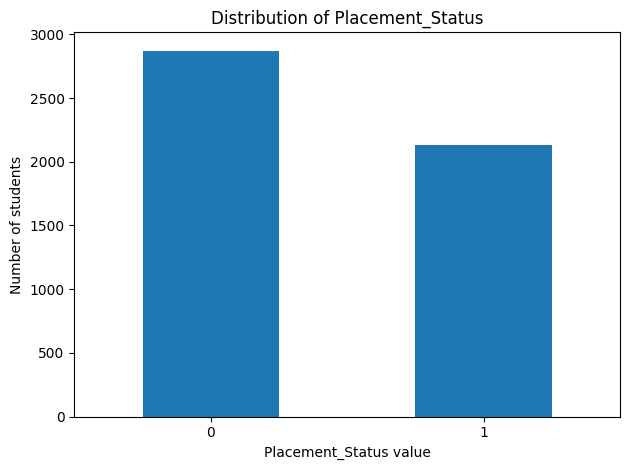

In [3]:
TARGET = "Placement_Status"

if TARGET not in df.columns:
    raise ValueError(
        f"Target column '{TARGET}' was not found. "
        "Check the column names printed in Cell 2."
    )

print("Missing target values:", df[TARGET].isna().sum())

print("\nTarget value counts:")
display(df[TARGET].value_counts(dropna=False).to_frame("Count"))

print("\nTarget percentages:")
display(
    (df[TARGET].value_counts(normalize=True, dropna=False) * 100)
    .round(2)
    .to_frame("Percentage")
)

df[TARGET].value_counts().plot(
    kind="bar",
    rot=0,
    title="Distribution of Placement_Status"
)
plt.xlabel("Placement_Status value")
plt.ylabel("Number of students")
plt.tight_layout()
plt.show()

Number of numerical features: 150


,count,mean,std,min,25%,50%,75%,max
UG_Required,5000.0,1.000000,0.000000,1.0,1.00,1.00,1.000,1.0
PG_Required_For_Target_Role,5000.0,0.127200,0.333230,0.0,0.00,0.00,0.000,1.0
Relevant_Degree_Required,5000.0,0.555200,0.496993,0.0,0.00,1.00,1.000,1.0
Year,5000.0,3.650600,0.476828,3.0,3.00,4.00,4.000,4.0
CGPA,5000.0,7.728904,0.850024,5.2,7.14,7.72,8.310,10.0
...,...,...,...,...,...,...,...,...
Teamwork,5000.0,60.015660,10.993247,20.0,52.60,60.10,67.400,96.3
Leadership,5000.0,53.700240,13.439659,15.0,44.50,53.50,63.100,100.0
Problem_Solving,5000.0,60.495320,11.161704,20.0,52.90,60.50,68.100,100.0
Presentation,5000.0,54.932600,12.069931,20.0,47.00,54.90,63.025,100.0


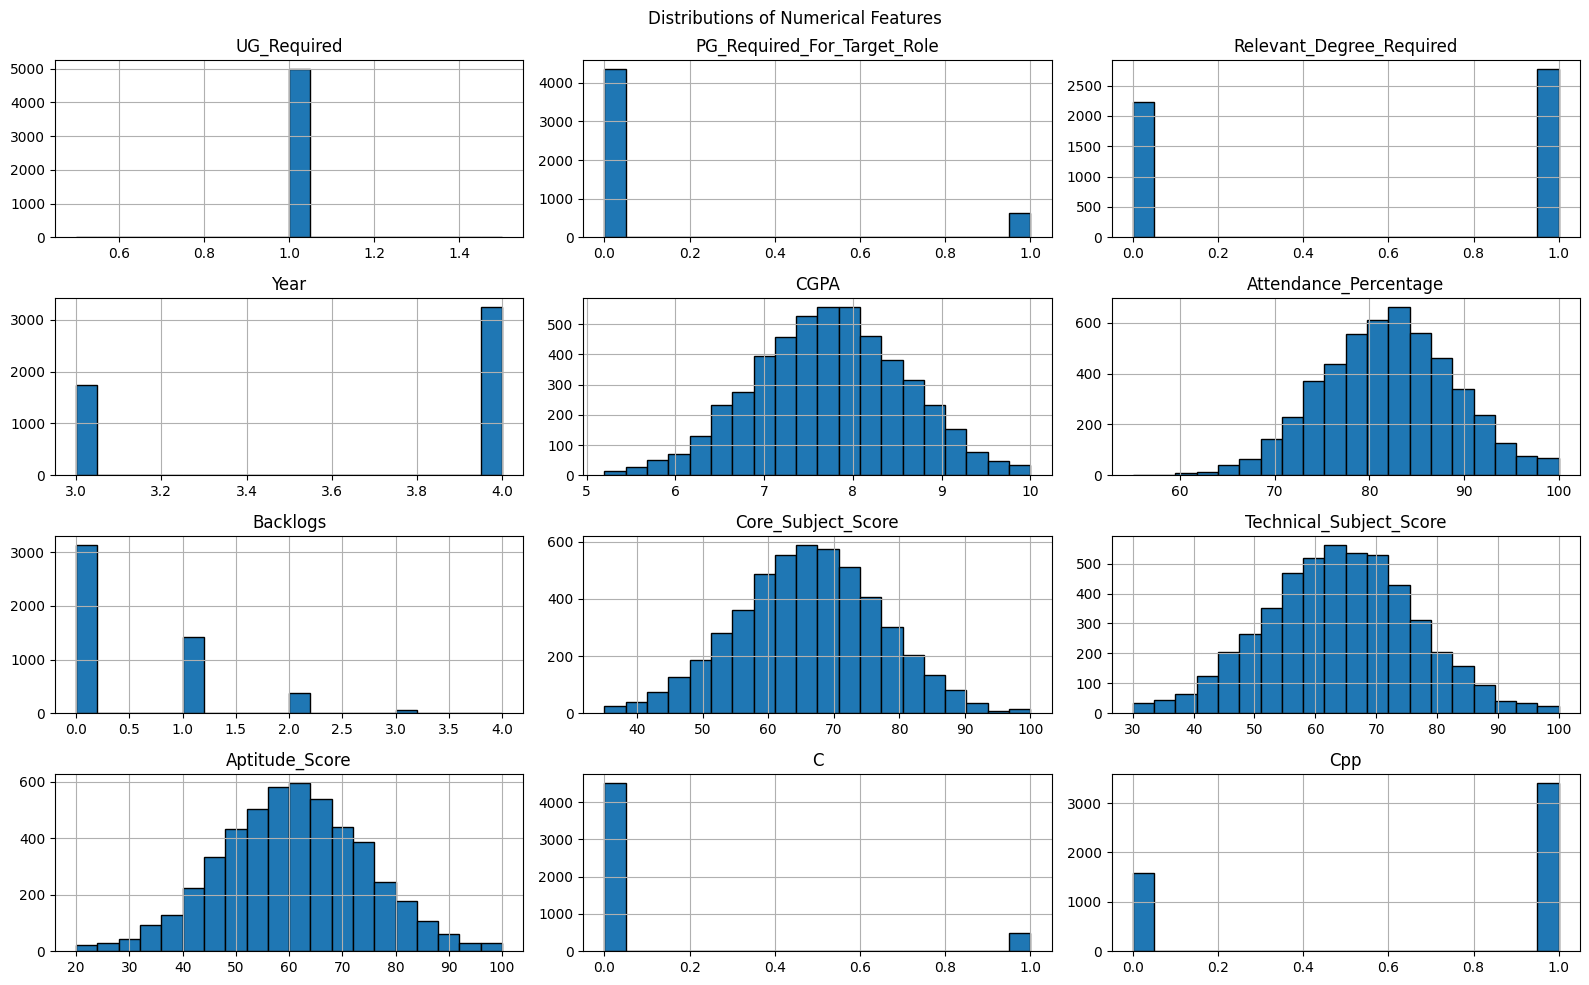

In [4]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

# Exclude the target from descriptive statistics
numeric_features = [c for c in numeric_cols if c != TARGET]

print("Number of numerical features:", len(numeric_features))

display(df[numeric_features].describe().T)

# Plot distributions for up to 12 numerical features
plot_cols = numeric_features[:12]

if plot_cols:
    df[plot_cols].hist(figsize=(16, 10), bins=20, edgecolor="black")
    plt.suptitle("Distributions of Numerical Features")
    plt.tight_layout()
    plt.show()
else:
    print("No numerical features found.")

In [5]:
categorical_cols = df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Categorical columns:", len(categorical_cols))
print(categorical_cols)

for col in categorical_cols:
    print(f"\n{'=' * 60}")
    print("Column:", col)
    print("Unique values:", df[col].nunique(dropna=False))
    display(
        df[col]
        .value_counts(dropna=False)
        .head(20)
        .to_frame("Count")
    )

Categorical columns: 6
['Student_ID', 'Data_Source', 'Education_Level', 'UG_Degree', 'PG_Specialization', 'Branch']

Column: Student_ID
Unique values: 5000


,Count
Student_ID,
SYN_05000,1
SYN_00001,1
SYN_00002,1
SYN_00003,1
SYN_00004,1
SYN_00005,1
SYN_00006,1
SYN_00007,1
SYN_04984,1



Column: Data_Source
Unique values: 1


,Count
Data_Source,
Synthetic,5000



Column: Education_Level
Unique values: 2


...

,Count
UG_Degree,
B.Tech CSE,1644
B.Tech IT,901
B.Tech ECE,798
B.Tech Mechanical,692
B.Tech Civil,493
B.Tech EEE,472



Column: PG_Specialization
Unique values: 6


,Count
PG_Specialization,
NaN,4125
M.E.,215
M.Sc,175
M.Tech,169
MCA,168
MBA,148



Column: Branch
Unique values: 6


,Count
Branch,
CSE,1644
IT,901
ECE,798
Mechanical,692
Civil,493
EEE,472


Students per branch:


,Student_Count
Branch,
CSE,1644
IT,901
ECE,798
Mechanical,692
Civil,493
EEE,472



Placement-status counts by branch:


Placement_Status,0,1,All
Branch,,,
CSE,671,973,1644
Civil,364,129,493
ECE,556,242,798
EEE,344,128,472
IT,465,436,901
Mechanical,472,220,692
All,2872,2128,5000



Percentage distribution of target values within each branch:


Placement_Status,0,1
Branch,,
CSE,40.82,59.18
Civil,73.83,26.17
ECE,69.67,30.33
EEE,72.88,27.12
IT,51.61,48.39
Mechanical,68.21,31.79


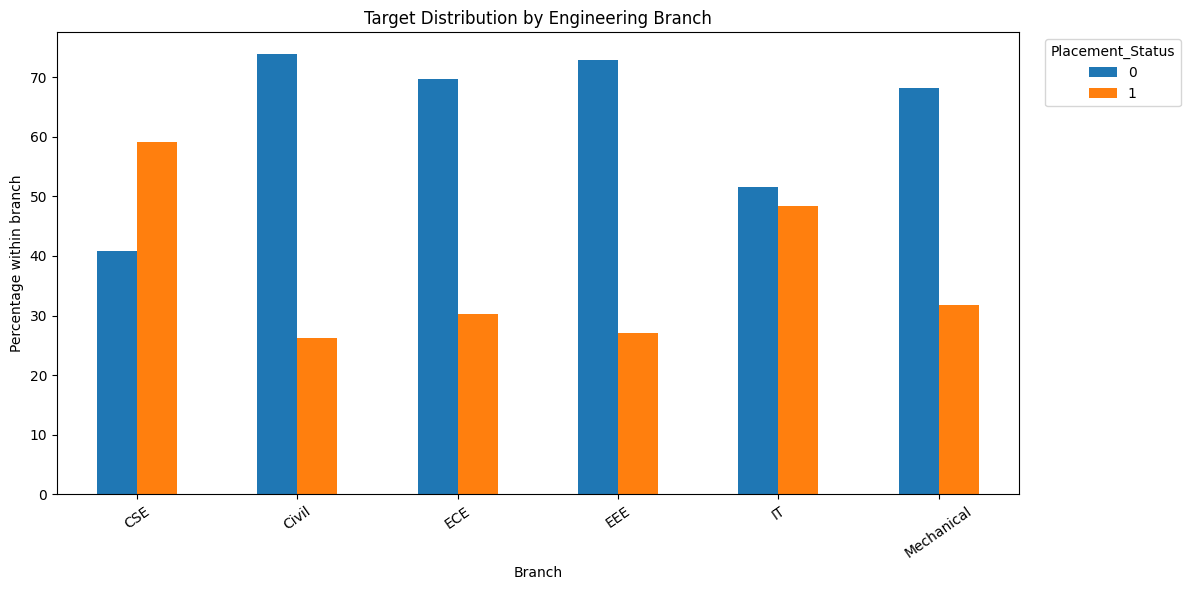

In [6]:
branch_col = "Branch"

if branch_col in df.columns:
    branch_counts = df[branch_col].value_counts(dropna=False)
    print("Students per branch:")
    display(branch_counts.to_frame("Student_Count"))

    branch_target_table = pd.crosstab(
        df[branch_col],
        df[TARGET],
        margins=True
    )

    print("\nPlacement-status counts by branch:")
    display(branch_target_table)

    branch_rates = pd.crosstab(
        df[branch_col],
        df[TARGET],
        normalize="index"
    ) * 100

    print("\nPercentage distribution of target values within each branch:")
    display(branch_rates.round(2))

    branch_rates.plot(
        kind="bar",
        figsize=(12, 6),
        rot=35
    )
    plt.title("Target Distribution by Engineering Branch")
    plt.xlabel("Branch")
    plt.ylabel("Percentage within branch")
    plt.legend(title=TARGET, bbox_to_anchor=(1.02, 1))
    plt.tight_layout()
    plt.show()
else:
    print(f"Column '{branch_col}' not found. Check the actual branch column name.")

Available features for analysis: ['CGPA', 'Attendance_Percentage', 'Backlogs', 'Project_Count', 'Relevant_Project_Count', 'Internship', 'Internship_Duration_Months', 'Certification_Count', 'Aptitude_Score', 'Technical_Subject_Score', 'Core_Subject_Score']

Feature: CGPA


,count,mean,median,std
Placement_Status,,,,
0,2872,7.553,7.55,0.830
1,2128,7.966,7.96,0.819


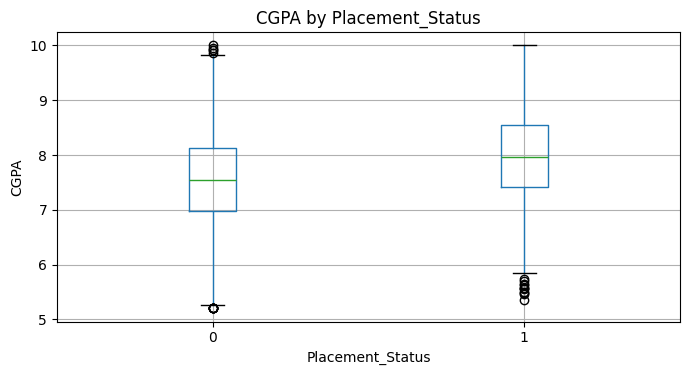


Feature: Attendance_Percentage


,count,mean,median,std
Placement_Status,,,,
0,2872,81.964,81.95,6.966
1,2128,82.020,82.10,7.060


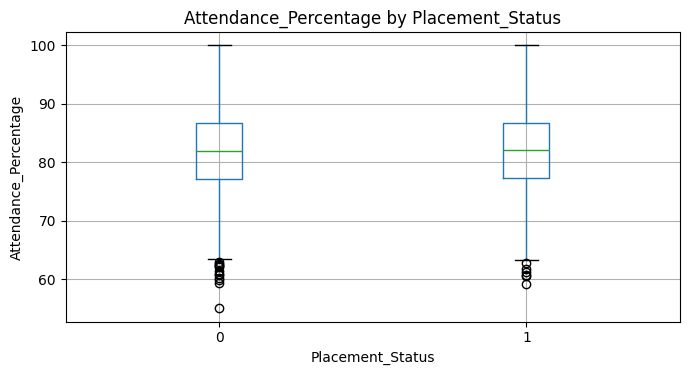


Feature: Backlogs


,count,mean,median,std
Placement_Status,,,,
0,2872,0.520,0.0,0.714
1,2128,0.409,0.0,0.658


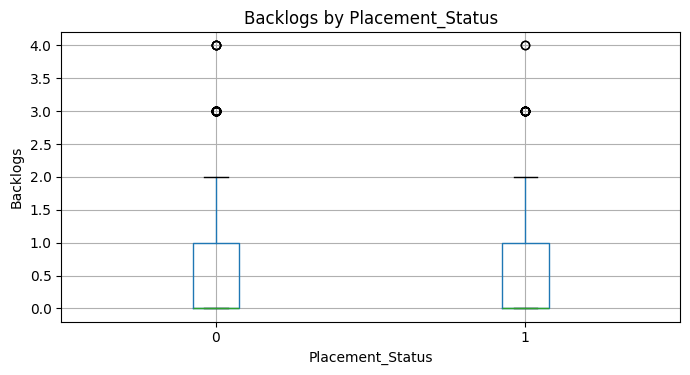


Feature: Project_Count


,count,mean,median,std
Placement_Status,,,,
0,2872,1.856,2.0,1.388
1,2128,2.319,2.0,1.525


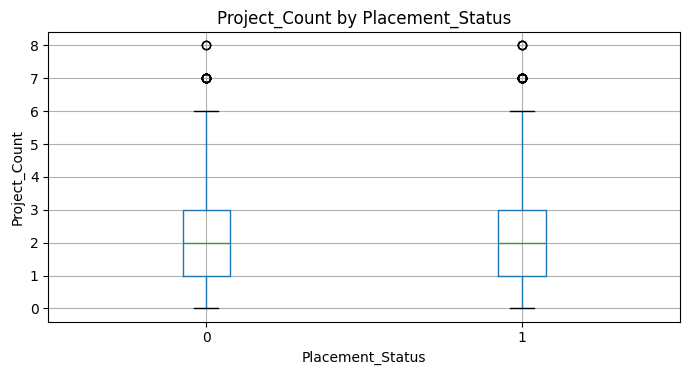


Feature: Relevant_Project_Count


,count,mean,median,std
Placement_Status,,,,
0,2872,1.189,1.0,1.097
1,2128,1.508,1.0,1.216


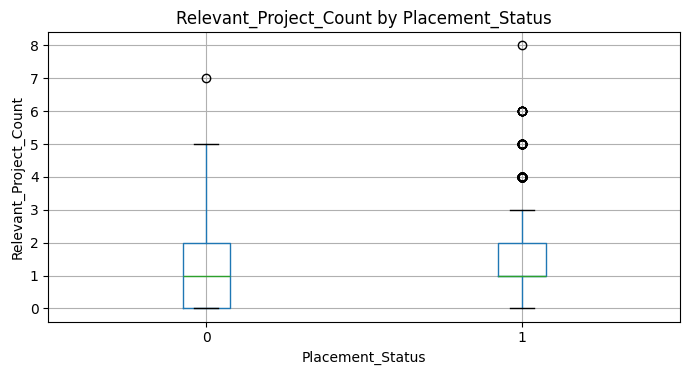


Feature: Internship


,count,mean,median,std
Placement_Status,,,,
0,2872,0.251,0.0,0.434
1,2128,0.455,0.0,0.498


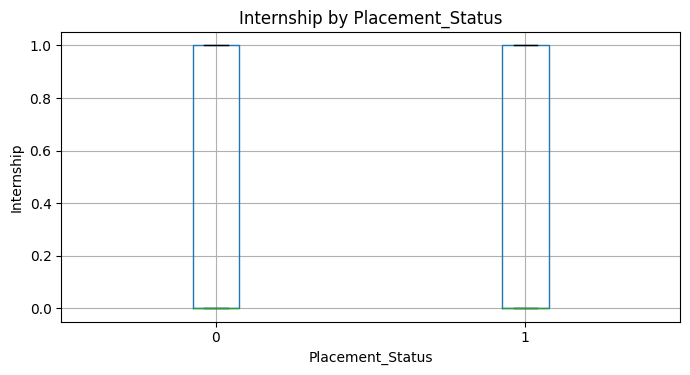


Feature: Internship_Duration_Months


,count,mean,median,std
Placement_Status,,,,
0,2872,0.743,0.0,1.510
1,2128,1.345,0.0,1.825


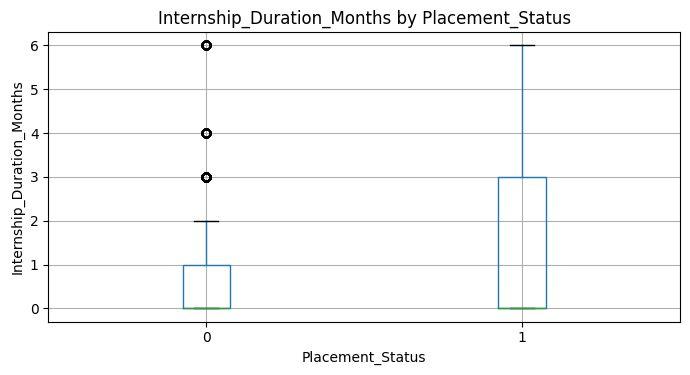


Feature: Certification_Count


,count,mean,median,std
Placement_Status,,,,
0,2872,1.468,1.0,1.245
1,2128,1.692,1.0,1.340


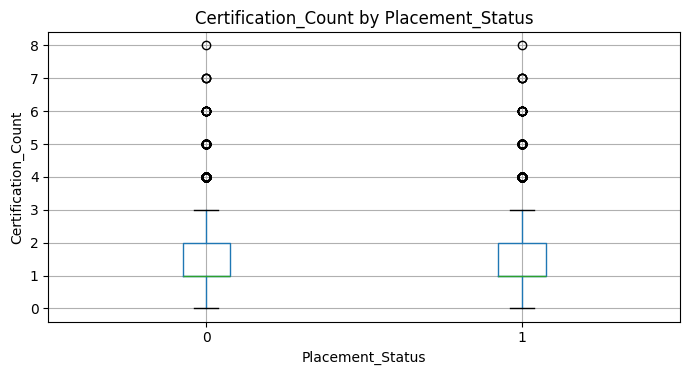


Feature: Aptitude_Score


,count,mean,median,std
Placement_Status,,,,
0,2872,58.939,59.1,13.567
1,2128,63.089,63.1,13.511


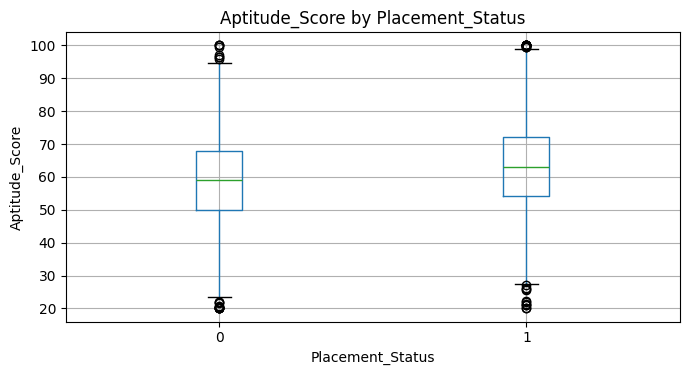


Feature: Technical_Subject_Score


,count,mean,median,std
Placement_Status,,,,
0,2872,62.267,62.15,12.174
1,2128,66.393,66.80,12.175


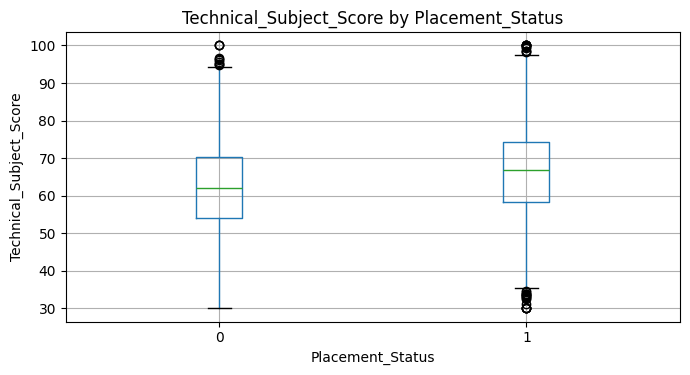


Feature: Core_Subject_Score


,count,mean,median,std
Placement_Status,,,,
0,2872,64.540,64.6,10.958
1,2128,68.223,68.3,10.591


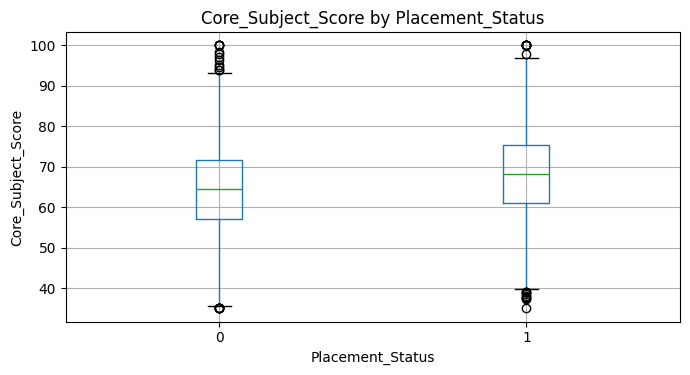

In [7]:
candidate_features = [
    "CGPA",
    "Attendance_Percentage",
    "Backlogs",
    "Project_Count",
    "Relevant_Project_Count",
    "Internship",
    "Internship_Duration_Months",
    "Certification_Count",
    "Aptitude_Score",
    "Technical_Subject_Score",
    "Core_Subject_Score"
]

available_features = [
    col for col in candidate_features
    if col in df.columns and col != TARGET
]

print("Available features for analysis:", available_features)

for col in available_features:
    print(f"\nFeature: {col}")

    if pd.api.types.is_numeric_dtype(df[col]):
        summary = df.groupby(TARGET, dropna=False)[col].agg(
            ["count", "mean", "median", "std"]
        )
        display(summary.round(3))

        df.boxplot(column=col, by=TARGET, figsize=(7, 4))
        plt.title(f"{col} by {TARGET}")
        plt.suptitle("")
        plt.xlabel(TARGET)
        plt.ylabel(col)
        plt.tight_layout()
        plt.show()
    else:
        display(pd.crosstab(df[col], df[TARGET]))

In [8]:
missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)

print("Columns containing missing values:")
if missing.empty:
    print("No missing values found.")
else:
    missing_report = pd.DataFrame({
        "Missing_Count": missing,
        "Missing_Percentage": (missing / len(df) * 100).round(2)
    })
    display(missing_report)

print("\nExact duplicate rows:", df.duplicated().sum())

if "Student_ID" in df.columns:
    print("Missing Student_ID values:", df["Student_ID"].isna().sum())
    print("Duplicate Student_ID values:", df["Student_ID"].duplicated().sum())

Columns containing missing values:


,Missing_Count,Missing_Percentage
PG_Specialization,4125,82.5



Exact duplicate rows: 0
Missing Student_ID values: 0
Duplicate Student_ID values: 0


Numerical features most associated with the target:


,Correlation
CGPA,0.240274
Internship,0.213558
DSA,0.190865
JavaScript,0.181552
CSS,0.180526
Internship_Duration_Months,0.177619
Core_Subject_Score,0.166233
Technical_Subject_Score,0.165292
MySQL,0.165060
HTML,0.159646


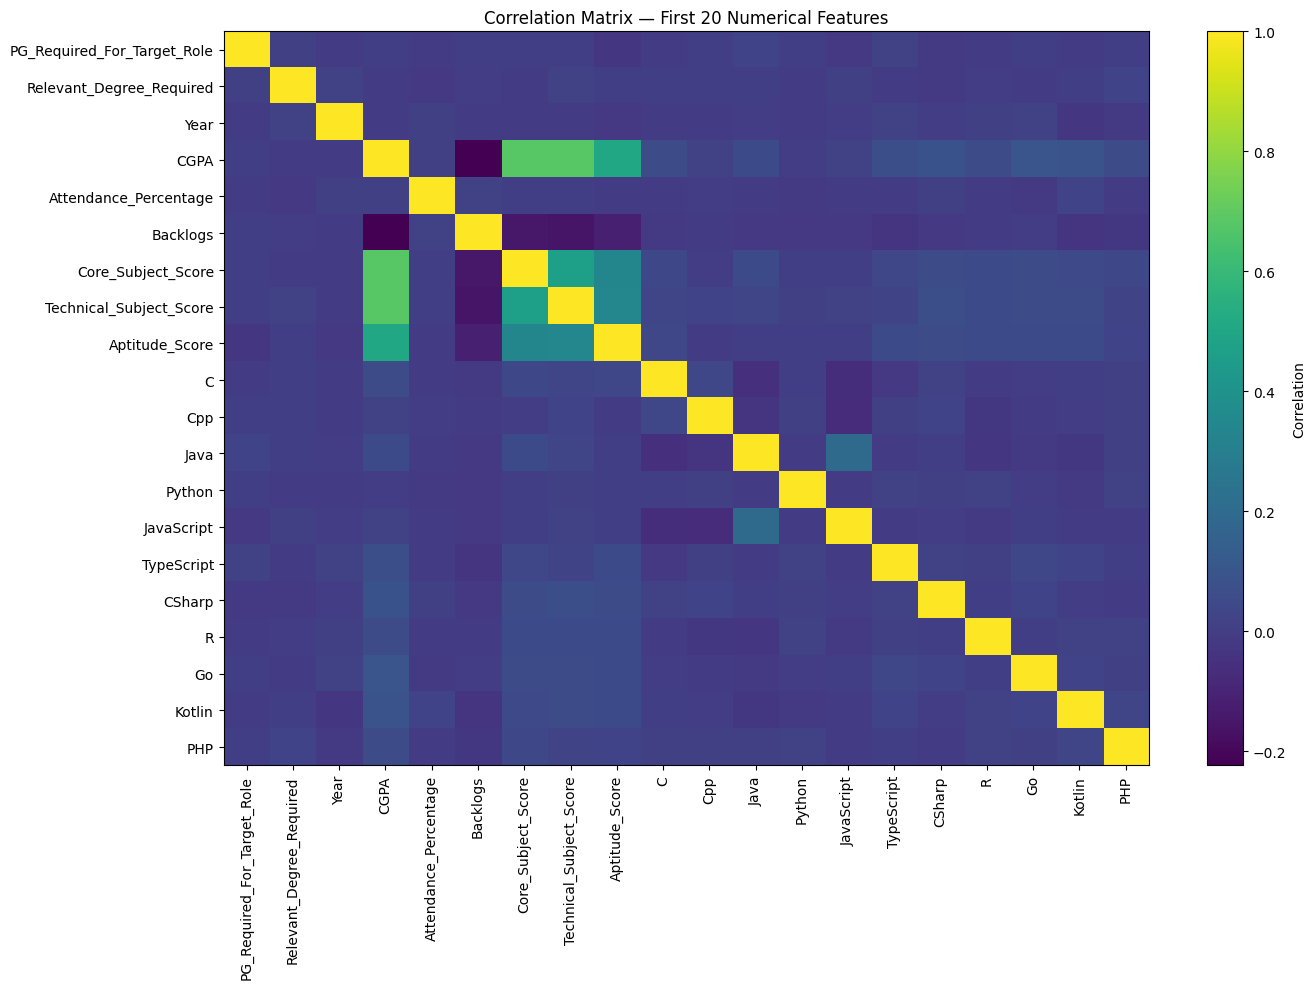

In [9]:
corr_cols = [
    col for col in numeric_features
    if df[col].nunique(dropna=True) > 1
]

if len(corr_cols) >= 2:
    corr = df[corr_cols].corr()

    # Show features most correlated with the numeric target, if valid
    if TARGET in df.columns and pd.api.types.is_numeric_dtype(df[TARGET]):
        target_corr = (
            df[corr_cols]
            .corrwith(pd.to_numeric(df[TARGET], errors="coerce"))
            .dropna()
            .sort_values(key=lambda s: s.abs(), ascending=False)
        )

        print("Numerical features most associated with the target:")
        display(target_corr.head(20).to_frame("Correlation"))

    # Plot the correlation matrix for a manageable subset
    heatmap_cols = corr_cols[:20]
    corr_subset = df[heatmap_cols].corr()

    plt.figure(figsize=(14, 10))
    plt.imshow(corr_subset, aspect="auto", interpolation="nearest")
    plt.colorbar(label="Correlation")
    plt.xticks(range(len(heatmap_cols)), heatmap_cols, rotation=90)
    plt.yticks(range(len(heatmap_cols)), heatmap_cols)
    plt.title("Correlation Matrix — First 20 Numerical Features")
    plt.tight_layout()
    plt.show()
else:
    print("Not enough varying numerical features for correlation analysis.")

In [10]:
print("Constant columns (only one non-missing unique value):")

constant_cols = [
    col for col in df.columns
    if col != TARGET and df[col].nunique(dropna=True) <= 1
]

print(constant_cols if constant_cols else "None")

print("\nColumns whose names may require leakage review:")

keywords = [
    "placement", "employability", "hired", "selected",
    "outcome", "target", "required_for", "eligible"
]

review_cols = [
    col for col in df.columns
    if col != TARGET and any(k in col.lower() for k in keywords)
]

print(review_cols if review_cols else "No obvious name matches found.")

print(
    "\nReview these columns' definitions and generation process "
    "before using them as model inputs."
)

Constant columns (only one non-missing unique value):
['Data_Source', 'UG_Required']

Columns whose names may require leakage review:
['PG_Required_For_Target_Role']

Review these columns' definitions and generation process before using them as model inputs.


In [12]:
eda_summary = {
    "Rows": len(df),
    "Columns": len(df.columns),
    "Exact_Duplicate_Rows": int(df.duplicated().sum()),
    "Missing_Cells": int(df.isna().sum().sum()),
    "Columns_With_Missing_Values": int((df.isna().sum() > 0).sum()),
    "Numerical_Columns": len(df.select_dtypes(include=np.number).columns),
    "Categorical_Columns": len(
        df.select_dtypes(include=["object", "category", "bool"]).columns
    ),
    "Target_Column": TARGET,
    "Target_Missing_Values": int(df[TARGET].isna().sum())
}

summary_df = pd.DataFrame(
    eda_summary.items(),
    columns=["Metric", "Value"]
)

display(summary_df)

summary_df.to_csv("phase2_eda_summary.csv", index=False)
print("Saved: phase2_eda_summary.csv")

,Metric,Value
0,Rows,5000
1,Columns,157
2,Exact_Duplicate_Rows,0
3,Missing_Cells,4125
4,Columns_With_Missing_Values,1
5,Numerical_Columns,151
6,Categorical_Columns,6
7,Target_Column,Placement_Status
8,Target_Missing_Values,0


Saved: phase2_eda_summary.csv
